# Cookie Cats A/B Test Analysis

## Business Question
Does moving the first gate from level 30 to level 40 change how many players are still playing **7 days after install**?

## Background
Cookie Cats is a mobile puzzle game. At certain levels a *gate* forces players to wait (or pay) before they can continue.
New players were randomly assigned to one of two versions:

- **gate_30** (control): first gate at level 30
- **gate_40** (treatment): first gate at level 40

## Hypothesis
Gate 30 will retain more players at day 7. An earlier break interrupts play before players get bored, which may make them come back later.

## Metrics & Decision Rule
| | Metric | Role |
|---|---|---|
| Primary | `retention_7`: player came back 7 days after install | decision metric |
| Secondary | `retention_1`: player came back 1 day after install | supporting evidence |

Two-sided test, significance level α = 0.05. I will recommend gate_30 only if its 7-day retention is significantly higher **and** the confidence interval for the difference is entirely above zero.

## Notebook Outline
1. Data quality checks
2. Experiment health checks (sample ratio, filtering)
3. Retention rates and frequentist tests (z-test, confidence interval, power)
4. Bayesian analysis
5. Did the gate change how much people played?
6. Business impact
7. Conclusion and limitations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import (proportions_ztest,
                                          confint_proportions_2indep,
                                          proportion_effectsize)
from statsmodels.stats.power import NormalIndPower

SEED = 42                      # fixed seed so the Bayesian simulation is reproducible
rng = np.random.default_rng(SEED)
COLORS = {'gate_30': '#2a9d8f', 'gate_40': '#e76f51'}
sns.set_theme(style='whitegrid')

df = pd.read_csv('cookie_cats.csv')
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


# 1. Data Quality Checks

In [2]:
print('Rows:', len(df))
print('Duplicate user ids:', df['userid'].duplicated().sum())
print('Missing values:', df.isna().sum().sum())
df['sum_gamerounds'].describe()

Rows: 90189
Duplicate user ids: 0
Missing values: 0


count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [3]:
# The maximum looks suspicious, so look at the most extreme players
df.sort_values('sum_gamerounds', ascending=False).head(3)

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False


**Observations**
- No duplicates and no missing values.
- `sum_gamerounds` is very skewed. The median player played 16 rounds, but one player logged **49,854 rounds** in 14 days. That is roughly 3,500 rounds a day, and the same player did not even return on day 1. This is almost certainly a logging error.
- The retention metrics are 0/1 flags, so one player hardly changes them, and I keep the row for the retention tests. The outlier only matters for gameplay-volume analysis (section 5), where I use measures that are not distorted by extreme values.

# 2. Experiment Health Checks

## 2.1 Sample Ratio Mismatch (SRM)
Players were meant to be split 50/50. If the observed split differs more than chance allows, the assignment or logging may be broken. That would be a warning sign for every result that follows, so this check comes first.

In [4]:
counts = df['version'].value_counts().sort_index()
print(counts)
print(f"Share in gate_30: {counts['gate_30'] / counts.sum():.2%}")

chi2, srm_p = stats.chisquare(counts)          # expected: equal counts
print(f"Chi-square = {chi2:.2f}, p-value = {srm_p:.4f}")

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64
Share in gate_30: 49.56%
Chi-square = 6.90, p-value = 0.0086


**Interpretation:** the split is 49.6% / 50.4%. That looks almost equal, but with 90,000 players even a small imbalance is unlikely to be chance (p ≈ 0.009 < 0.05). So there is a **sample ratio mismatch**.

The data cannot tell us the cause (assignment bug, tracking loss in one version, bot filtering, ...). The imbalance is small (≈ 0.9 percentage points) and the metrics are rates, so I continue with the analysis. I list SRM as a **limitation**, and in a real company I would ask the data engineering team to investigate before shipping a decision.

## 2.2 Filtering Strategy: Modified Intention to Treat (mITT)
A player who never played a single round never reached either gate, so the gate had no chance to affect them. Including them only adds noise to both groups.

I remove players with `sum_gamerounds = 0`. This is safe **only if** both groups lose a similar share of players. Otherwise the filter itself would create a difference, so I test that first.

In [5]:
zero = df[df['sum_gamerounds'] == 0]['version'].value_counts().sort_index()
print('Players with 0 rounds:\n', zero, sep='')
print('\nShare with 0 rounds:\n', (zero / counts).round(4), sep='')

z, p_zero = proportions_ztest(zero, counts)
print(f"\nTest of equal zero-round share: p-value = {p_zero:.3f}")

Players with 0 rounds:
version
gate_30    1937
gate_40    2057
Name: count, dtype: int64

Share with 0 rounds:
version
gate_30    0.0433
gate_40    0.0452
Name: count, dtype: float64

Test of equal zero-round share: p-value = 0.169


The zero-round share is 4.3% vs 4.5% and the difference is not significant (p ≈ 0.17). Removing these 3,994 players does not favour either group, so the filter is safe.

In [6]:
df_0 = df[df['sum_gamerounds'] > 0]
gate30 = df_0[df_0['version'] == 'gate_30']
gate40 = df_0[df_0['version'] == 'gate_40']
print(df_0['version'].value_counts().sort_index())
print('Players removed:', len(df) - len(df_0))

version
gate_30    42763
gate_40    43432
Name: count, dtype: int64
Players removed: 3994


## 2.3 A Filter I Tried and Rejected: "Only Players Who Reached the Gate"
My first idea was to keep only players who actually reached their gate (≥ 30 rounds for gate_30, ≥ 40 rounds for gate_40), because only they "felt" the gate.

In [7]:
reached = df_0[((df_0['version'] == 'gate_30') & (df_0['sum_gamerounds'] >= 30)) |
               ((df_0['version'] == 'gate_40') & (df_0['sum_gamerounds'] >= 40))]

summary = pd.DataFrame({
    'players (mITT)':      df_0['version'].value_counts(),
    'reached their gate':  reached['version'].value_counts(),
})
summary['% never reached gate'] = (1 - summary['reached their gate'] / summary['players (mITT)']) * 100
summary['7-day retention among reached (%)'] = reached.groupby('version')['retention_7'].mean() * 100
summary.round(1)

,players (mITT),reached their gate,% never reached gate,7-day retention among reached (%)
version,,,,
gate_30,42763,16656,61.1,43.9
gate_40,43432,13827,68.2,48.5


**Why this filter is wrong: survivor bias.**

After this filter gate_40 *appears* to retain better (≈ 49% vs ≈ 44%). But the two groups are no longer comparable:
- Reaching round 40 takes more engagement than reaching round 30, so the gate_40 group keeps only its most dedicated players (68% are dropped vs 61% for gate_30).
- `sum_gamerounds` is measured **after** assignment, so it is itself affected by the treatment. Filtering on a post-treatment variable breaks the randomization that makes an A/B test valid.

So I go back to comparing the **full randomized groups** (mITT), where the only systematic difference between the groups is the gate position.

# 3. Retention Rates and Frequentist Tests

In [8]:
rows = []
for metric in ['retention_1', 'retention_7']:
    p30, p40 = gate30[metric].mean(), gate40[metric].mean()
    rows.append({'metric': metric,
                 'gate_30 (%)': p30 * 100,
                 'gate_40 (%)': p40 * 100,
                 'difference (pp)': (p30 - p40) * 100,
                 'relative lift (%)': (p30 - p40) / p40 * 100})
rates = pd.DataFrame(rows).set_index('metric').round(2)
rates

,gate_30 (%),gate_40 (%),difference (pp),relative lift (%)
metric,,,,
retention_1,46.75,46.22,0.54,1.16
retention_7,19.84,19.03,0.81,4.27


Gate_30 retains **19.84%** of players at day 7 vs **19.03%** for gate_40. That is a gap of **0.81 percentage points (pp)**, or **4.3% more retained players relative to gate_40**.

*Note on units:* "percentage points" is the absolute gap between two percentages (19.84 − 19.03). "Percent" (relative lift) is that gap divided by the baseline. A/B reports must keep these apart.

## 3.1 Two-Proportion Z-Test
- **H₀:** gate_30 and gate_40 have the same true retention rate.
- **H₁:** the rates differ (two-sided).

In [9]:
n = np.array([len(gate30), len(gate40)])
test_rows = []
for metric in ['retention_7', 'retention_1']:
    retained = np.array([gate30[metric].sum(), gate40[metric].sum()])
    z_stat, p_val = proportions_ztest(retained, n)
    low, high = confint_proportions_2indep(retained[0], n[0], retained[1], n[1], method='wald')
    test_rows.append({'metric': metric, 'z': z_stat, 'p-value': p_val,
                      '95% CI low (pp)': low * 100, '95% CI high (pp)': high * 100,
                      'significant at 0.05': p_val < 0.05})
tests = pd.DataFrame(test_rows).set_index('metric').round(4)
tests

,z,p-value,95% CI low (pp),95% CI high (pp),significant at 0.05
metric,,,,,
retention_7,3.0130,0.0026,0.2838,1.3406,True
retention_1,1.5774,0.1147,-0.1300,1.2019,False


**How to read the z-statistic.** It says how many standard errors the observed difference is from zero (what H₀ predicts):

| z | Meaning | Under H₀ this is... |
|---|---|---|
| 0 | No difference at all | exactly what we expect |
| 1 | 1 standard error away | common |
| 2 | 2 standard errors away | unusual (≈ 5% chance) |
| 3 | 3 standard errors away | very unusual (≈ 0.3% chance) |

**7-day retention (primary):** z ≈ 3.01, p ≈ 0.0026. If the gate position truly made no difference, a gap this large would appear by random sampling only about 0.26% of the time. That is well below α = 0.05, so **I reject H₀**.

**1-day retention (secondary):** p ≈ 0.11, **not significant**. On day 1 the data cannot distinguish the two versions.

## 3.2 Confidence Intervals
- **7-day retention:** the 95% CI for the difference (gate_30 − gate_40) runs from about **+0.28 pp to +1.34 pp**. The whole interval is above zero, so even the most pessimistic plausible value still favours gate_30.
- **1-day retention:** the CI includes zero (about −0.13 pp to +1.20 pp), so "no difference" is still plausible on day 1.

The 7-day effect is real but **small**: somewhere between roughly 0.3 and 1.3 extra retained players per 100 installs.

## 3.3 Power Check
Was the experiment large enough to detect effects of this size? Power is the probability of detecting a true effect. The **minimum detectable effect (MDE)** is the smallest true difference the test would detect 80% of the time.

In [10]:
power_calc = NormalIndPower()
ratio = n[1] / n[0]

for metric in ['retention_7', 'retention_1']:
    base = gate40[metric].mean()
    observed = gate30[metric].mean()
    power = power_calc.power(proportion_effectsize(observed, base), nobs1=n[0], ratio=ratio, alpha=0.05)
    # smallest absolute difference detectable with 80% power
    mde = next(d for d in np.arange(0.0001, 0.05, 0.0001)
               if power_calc.power(proportion_effectsize(base + d, base), nobs1=n[0], ratio=ratio, alpha=0.05) >= 0.8)
    print(f"{metric}: power for the observed difference = {power:.0%}, MDE (80% power) = {mde*100:.2f} pp")

retention_7: power for the observed difference = 85%, MDE (80% power) = 0.76 pp
retention_1: power for the observed difference = 35%, MDE (80% power) = 0.96 pp


- For 7-day retention the test had about **85% power** for the observed effect, so the experiment was large enough to trust the significant result.
- The MDE is about 0.76 pp for 7-day retention and about 0.96 pp for 1-day retention. The observed day-1 gap (≈ 0.5 pp) is well below what this test can reliably detect (only ≈ 35% power). So the non-significant day-1 result means **"too small to detect"**, not "proven to be zero".

# 4. Bayesian Analysis
The z-test tells us how surprising the data would be if there were no difference. It does **not** give the probability that gate_30 is better. A Bayesian analysis answers that directly.

Each group's true 7-day retention rate gets a **Beta posterior**: a uniform Beta(1, 1) prior, updated with the number of players who were and were not retained. I then draw 100,000 samples from each posterior and count how often gate_30's rate is higher.

In [11]:
alpha_prior, beta_prior = 1, 1
r30, r40 = gate30['retention_7'].sum(), gate40['retention_7'].sum()

post_30 = stats.beta(alpha_prior + r30, beta_prior + n[0] - r30)
post_40 = stats.beta(alpha_prior + r40, beta_prior + n[1] - r40)

samples_30 = post_30.rvs(100_000, random_state=rng)
samples_40 = post_40.rvs(100_000, random_state=rng)
diff_samples = samples_30 - samples_40

prob_30_better = (diff_samples > 0).mean()
cred_low, cred_high = np.percentile(diff_samples, [2.5, 97.5])
print(f"P(gate_30 has higher 7-day retention) = {prob_30_better:.2%}")
print(f"P(gate_40 has higher 7-day retention) = {1 - prob_30_better:.2%}")
print(f"95% credible interval for the difference: ({cred_low*100:.2f} pp, {cred_high*100:.2f} pp)")

P(gate_30 has higher 7-day retention) = 99.85%
P(gate_40 has higher 7-day retention) = 0.15%
95% credible interval for the difference: (0.28 pp, 1.34 pp)


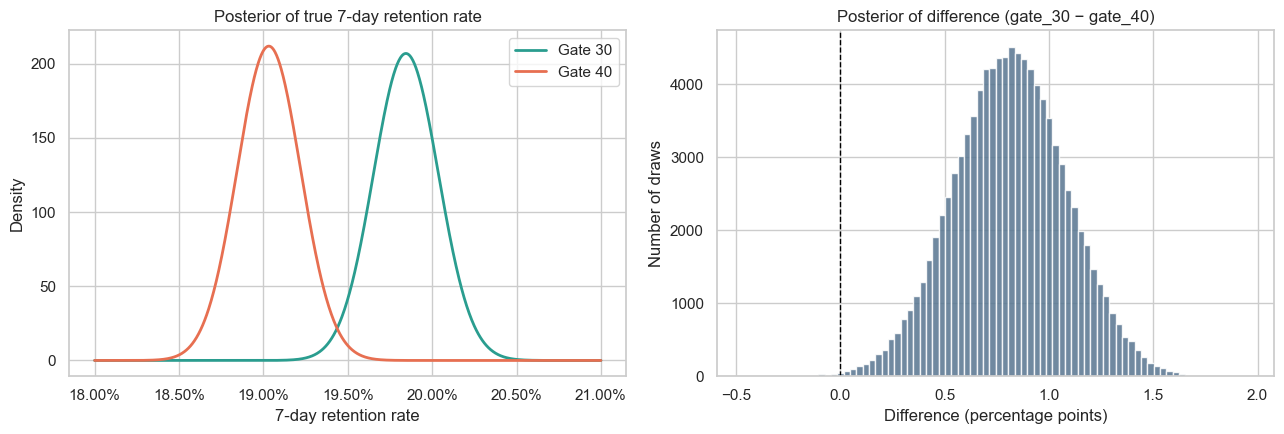

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

x = np.linspace(0.18, 0.21, 1000)
axes[0].plot(x, post_30.pdf(x), color=COLORS['gate_30'], lw=2, label='Gate 30')
axes[0].plot(x, post_40.pdf(x), color=COLORS['gate_40'], lw=2, label='Gate 40')
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set(title='Posterior of true 7-day retention rate', xlabel='7-day retention rate', ylabel='Density')
axes[0].legend()

axes[1].hist(diff_samples * 100, bins=80, color='#577590', alpha=0.85)
axes[1].axvline(0, color='black', ls='--', lw=1)
axes[1].set(title='Posterior of difference (gate_30 − gate_40)', xlabel='Difference (percentage points)', ylabel='Number of draws')

plt.tight_layout()
plt.show()

**Interpretation**
- The two posterior curves peak near 19.8% (gate_30) and 19.0% (gate_40) and overlap only slightly.
- About **99.85%** of the simulated differences are above zero. Given the data and a neutral prior, there is about a **99.9%** probability (the exact value is ≈ 99.87%; the simulation estimate varies slightly) that gate_30's true 7-day retention is higher.
- The 95% credible interval (≈ 0.28 to 1.34 pp) almost exactly matches the frequentist confidence interval. With this much data, both methods agree.

# 5. Did the Gate Change How Much People Played?
If gate_40 made players quit at the wall, fewer gate_40 players should get past round 40. To check, I plot the share of players who played **at least k rounds**. This "survival" view is not distorted by the 49,854-round outlier.

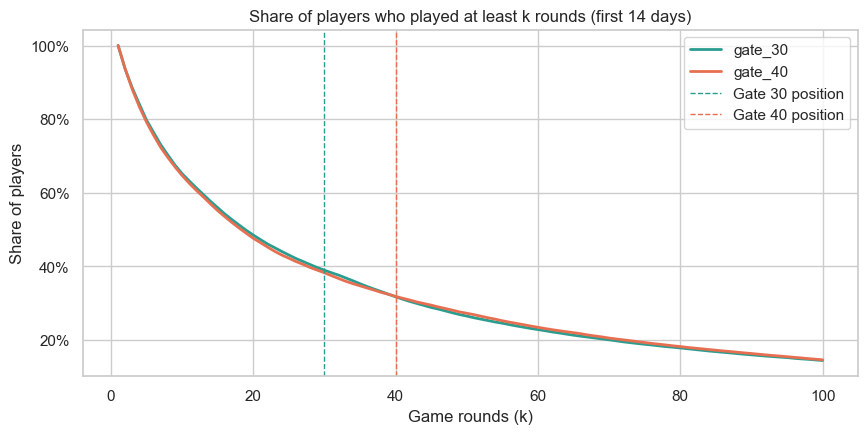

In [13]:
k = np.arange(1, 101)
surv = pd.DataFrame({v: [(g['sum_gamerounds'] >= i).mean() for i in k]
                     for v, g in df_0.groupby('version')}, index=k)

fig, ax = plt.subplots(figsize=(10, 4.5))
for v in surv:
    ax.plot(surv.index, surv[v], color=COLORS[v], lw=2, label=v)
ax.axvline(30, color=COLORS['gate_30'], ls='--', lw=1, label='Gate 30 position')
ax.axvline(40, color=COLORS['gate_40'], ls='--', lw=1, label='Gate 40 position')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title='Share of players who played at least k rounds (first 14 days)',
       xlabel='Game rounds (k)', ylabel='Share of players')
ax.legend()
plt.show()

In [14]:
checkpoints = surv.loc[[20, 30, 40, 50, 60]].mul(100).round(1)
checkpoints.index.name = 'played ≥ k rounds'
display(checkpoints)

u_stat, mw_p = stats.mannwhitneyu(gate30['sum_gamerounds'], gate40['sum_gamerounds'])
print(f"Median rounds: gate_30 = {gate30['sum_gamerounds'].median():.0f}, gate_40 = {gate40['sum_gamerounds'].median():.0f}")
print(f"Mann-Whitney U test p-value = {mw_p:.3f}")

,gate_30,gate_40
played ≥ k rounds,,
20,48.5,47.6
30,38.9,38.3
40,31.7,31.8
50,26.5,27.3
60,22.8,23.4


Median rounds: gate_30 = 18, gate_40 = 18
Mann-Whitney U test p-value = 0.116


**Interpretation (honest reading)**
- The two curves are almost identical. About 32% of players in **both** versions get past round 40, and neither curve shows a sudden cliff at its gate.
- Total rounds played are not significantly different (Mann-Whitney p ≈ 0.12; the median is 18 rounds in both groups).
- `sum_gamerounds` counts game rounds, including replays of failed levels, so it is **not** the same as the level a player reached. This dataset cannot show exactly where each player stopped.

**So the gate's effect shows up in whether players *come back* (7-day retention), not clearly in how many rounds they play.** One plausible reason: many players reach level 30–40 after day 1, which fits the gap being small and non-significant at day 1 but significant at day 7. This explanation is a hypothesis, not something this data proves.

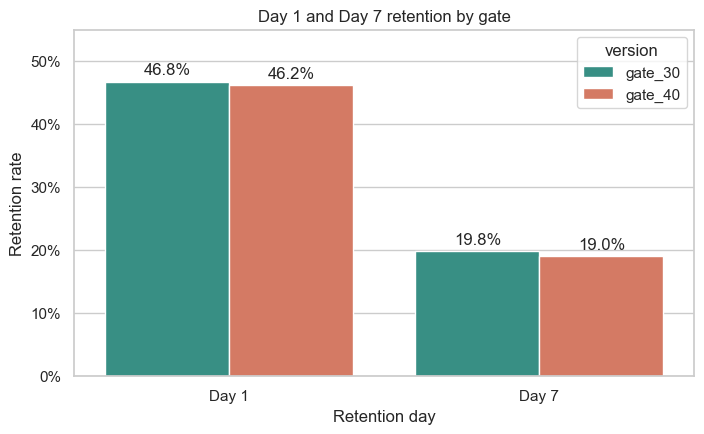

In [15]:
plot_df = (df_0.groupby('version')[['retention_1', 'retention_7']].mean()
               .rename(columns={'retention_1': 'Day 1', 'retention_7': 'Day 7'})
               .reset_index()
               .melt(id_vars='version', var_name='Retention day', value_name='Rate'))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=plot_df, x='Retention day', y='Rate', hue='version', palette=COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v*100:.1f}%' for v in container.datavalues], padding=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title='Day 1 and Day 7 retention by gate', ylabel='Retention rate', ylim=(0, 0.55))
plt.show()

The gap is about 0.5 pp on day 1 (not significant) and 0.8 pp on day 7 (significant).

# 6. Business Impact
To translate the retention difference into money, I need two inputs that this dataset does not contain, so these are **illustrative assumptions**:

| Assumption | Value | Why |
|---|---|---|
| New installs per day | 50,000 | retention applies to new install cohorts, not to all daily active users |
| Value of one extra 7-day-retained player | ₹5 | placeholder; a real analysis would use the incremental lifetime value (LTV) of a retained player |
| Effect stays constant for a year | yes | simplification |

**Formula:** extra retained players per day = installs × retention difference, and annual value = extra retained players per day × value per player × 365.

I use the confidence interval to give a range instead of a single number.

In [16]:
def annual_impact(diff, installs_per_day=50_000, value_per_player=5):
    # Extra 7-day-retained players per day and their annual value (in rupees)
    extra_players_per_day = installs_per_day * diff
    return extra_players_per_day, extra_players_per_day * value_per_player * 365

ci_low, ci_high = confint_proportions_2indep(r30, n[0], r40, n[1], method='wald')
observed_diff = gate30['retention_7'].mean() - gate40['retention_7'].mean()

scenarios = {'Worst case (CI low)': ci_low, 'Most likely (observed)': observed_diff, 'Best case (CI high)': ci_high}
impact = pd.DataFrame(
    [(name, d * 100, *annual_impact(d)) for name, d in scenarios.items()],
    columns=['scenario', 'retention diff (pp)', 'extra retained players / day', 'annual value (₹)']
).set_index('scenario')
impact.style.format({'retention diff (pp)': '{:.2f}', 'extra retained players / day': '{:,.0f}', 'annual value (₹)': '₹{:,.0f}'})

,retention diff (pp),extra retained players / day,annual value (₹)
scenario,,,
Worst case (CI low),0.28,142,"₹258,993"
Most likely (observed),0.81,406,"₹741,140"
Best case (CI high),1.34,670,"₹1,223,286"


Under these assumptions, switching to gate 40 would lose about **140 to 670 retained players per day**, worth roughly **₹2.6 lakh to ₹12.2 lakh a year** (most likely ≈ ₹7.4 lakh). The ranking (gate_30 is better) holds whatever the real value per player is. Only the size of the loss depends on the assumptions.

### Why no segment analysis?
A natural next step is to split players into segments (for example light vs heavy players). The only behavioural variable here, `sum_gamerounds`, is measured **after** assignment and is affected by the gate. Segmenting on it would bring back the same survivor bias as in section 2.3. A proper segment analysis would need **pre-assignment** attributes such as country, device or acquisition channel, which this dataset does not have.

# 7. Conclusion

I tested whether moving Cookie Cats' first gate from level 30 to level 40 changes 7-day retention, using 86,195 players who played at least one round.

| | Gate 30 | Gate 40 | Difference | Result |
|---|---|---|---|---|
| 7-day retention | 19.84% | 19.03% | +0.81 pp (+4.3% relative) | **significant** (p = 0.0026) |
| 1-day retention | 46.75% | 46.22% | +0.54 pp | not significant (p = 0.11) |

- **Frequentist:** 95% CI for the 7-day difference is +0.28 pp to +1.34 pp, entirely above zero, and the test had about 85% power.
- **Bayesian:** about a 99.9% probability that gate_30 has the higher true 7-day retention.
- **Gameplay:** the share of players reaching any given round is nearly identical. The gate changes whether players return, not visibly how far they play.
- **Business:** under illustrative assumptions (50,000 installs/day, ₹5 per retained player), moving to gate 40 would cost about ₹2.6–12.2 lakh a year.

## Recommendation
**Keep the gate at level 30.** The effect is small, but it is consistent, statistically reliable and points in the same direction under both methods.

## Limitations
- **Sample ratio mismatch** (49.6% / 50.4%, p ≈ 0.009). The cause should be investigated before acting on the result.
- Revenue figures are **illustrative**. A real decision needs actual install volume and the LTV of a retained player.
- Only 1-day and 7-day retention are available. Long-term retention, in-app purchases and novelty effects are not measured.
- `sum_gamerounds` counts rounds, not levels, so the data cannot show exactly where players stopped.